# 🚕 Taxi Trip Fare Prediction

> **Machine Learning Regression Project**

---

## 📌 1. Project Overview

This project focuses on predicting **taxi trip fares** using Machine Learning regression techniques.

The goal is to build a model that can estimate the fare of a taxi trip based on information such as trip characteristics, location, and time.

---

## 🎯 2. Problem Statement

Given information about a taxi trip, the objective is to **predict the fare amount** of that trip.

### Target Variable

**Fare Amount**

### Machine Learning Task

**Regression**

---

## 🔍 3. Project Objectives

Throughout this project, we will:

- Understand and explore the dataset.
- Identify and handle data quality issues.
- Perform Exploratory Data Analysis (EDA).
- Engineer meaningful features from the raw data.
- Prepare the data for Machine Learning.
- Train and compare multiple regression models.
- Evaluate model performance using appropriate regression metrics.
- Analyze prediction errors and model limitations.
- Save the final trained model for future use.

---

## 🛠️ 4. Project Workflow

```text
Data Understanding
        ↓
Exploratory Data Analysis
        ↓
Data Cleaning
        ↓
Feature Engineering
        ↓
Data Preprocessing
        ↓
Model Training
        ↓
Model Evaluation
        ↓
Error Analysis
        ↓
Model Saving
```

---

### 📚 Skills & Concepts

**Regression • EDA • Data Cleaning • Feature Engineering • Model Evaluation • Error Analysis • Machine Learning**

In [196]:
import sys
from pathlib import Path
import requests
import pandas as pd

print(sys.executable)

e:\AI-ML-Portfolio\.venv\Scripts\python.exe


In [197]:
raw_path = Path("../data/raw")
raw_path.mkdir(parents=True, exist_ok=True)

csv_path = raw_path / "nyc_taxi_fare_sample.csv"

In [198]:
url = "https://data.cityofnewyork.us/resource/gkne-dk5s.json"

params = {
    "$limit": 100_000
}

response = requests.get(url, params=params)
response.raise_for_status()

data = response.json()

df = pd.DataFrame(data)

print("Dataset extracted successfully!")
print(f"Shape: {df.shape}")

Dataset extracted successfully!
Shape: (100000, 18)


In [199]:
df.to_csv(csv_path, index=False)

print(f"Saved to: {csv_path}")

Saved to: ..\data\raw\nyc_taxi_fare_sample.csv


## 1. Data Understanding & Data Quality

Before building any Machine Learning model, it is important to understand the structure and quality of the dataset.

In this section, we will:

- Inspect the first and last records.
- Check the dataset dimensions.
- Examine the column names and data types.
- Identify missing values.
- Check for duplicate records.
- Explore basic statistical properties.

The goal is to understand the raw dataset and identify potential data quality issues before performing data cleaning and feature engineering.

### 1.1 Dataset Overview

In [200]:
df.head()

,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,trip_distance,pickup_longitude,pickup_latitude,store_and_fwd_flag,dropoff_longitude,dropoff_latitude,payment_type,fare_amount,mta_tax,tip_amount,tolls_amount,total_amount,imp_surcharge,rate_code
0,CMT,2014-11-23T20:31:29.000,2014-11-23T20:31:29.000,3,0,0,0,N,0,0,CSH,3,0.5,0,0,4,0.5,1
1,CMT,2014-04-16T13:45:06.000,2014-04-16T14:00:21.000,1,2.3999999999999999,-73.990026999999998,40.757196999999998,N,-73.958483999999999,40.765540000000001,CSH,12,0.5,0,0,12.5,0,1
2,CMT,2014-02-09T22:43:54.000,2014-02-09T23:06:21.000,2,9.3000000000000007,-73.870607000000007,40.773682000000001,N,-73.971969999999999,40.784683000000001,CRD,27.5,0.5,6.7599999999999998,5.3300000000000001,40.590000000000003,0.5,1
3,CMT,2014-10-27T23:15:23.000,2014-10-27T23:23:54.000,1,2.1000000000000001,-73.983610999999996,40.769134999999999,N,-73.974266999999998,40.748187999999999,CRD,8.5,0.5,2.3700000000000001,0,11.869999999999999,0.5,1
4,VTS,2014-09-14T01:32:00.000,2014-09-14T01:44:00.000,1,3.3599999999999999,-73.949010000000001,40.754086999999998,NaN,-73.960682000000006,40.712792,CRD,12.5,0.5,2.6000000000000001,0,16.100000000000001,0.5,1


In [201]:
df.tail()

,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,trip_distance,pickup_longitude,pickup_latitude,store_and_fwd_flag,dropoff_longitude,dropoff_latitude,payment_type,fare_amount,mta_tax,tip_amount,tolls_amount,total_amount,imp_surcharge,rate_code
99995,CMT,2014-03-03T19:22:55.000,2014-03-03T19:37:18.000,1,5.5999999999999996,0,0,N,0,0,CRD,18.5,0.5,4,0,24,1,1
99996,CMT,2014-10-03T00:33:39.000,2014-10-03T00:39:47.000,1,2,-73.967823999999993,40.772005,N,-73.991591999999997,40.760111000000002,CSH,8,0.5,0,0,9,0.5,1
99997,CMT,2014-12-10T02:16:46.000,2014-12-10T02:17:27.000,1,0,-73.992046000000002,40.731065999999998,N,-73.992448999999993,40.730454999999999,CRD,49,0,5,0,54,0,5
99998,CMT,2014-04-14T17:56:46.000,2014-04-14T18:01:01.000,1,0.80000000000000004,-73.999904000000001,40.733015000000002,N,-74.006597999999997,40.738103000000002,CSH,5,0.5,0,0,6.5,1,1
99999,CMT,2014-10-24T22:46:01.000,2014-10-24T23:06:41.000,2,4.5,-73.952640000000002,40.780622999999999,N,-73.925573,40.761781999999997,CSH,17.5,0.5,0,0,18.5,0.5,1


In [202]:
df.shape

(100000, 18)

In [203]:
df.columns

Index(['vendor_id', 'pickup_datetime', 'dropoff_datetime', 'passenger_count',
       'trip_distance', 'pickup_longitude', 'pickup_latitude',
       'store_and_fwd_flag', 'dropoff_longitude', 'dropoff_latitude',
       'payment_type', 'fare_amount', 'mta_tax', 'tip_amount', 'tolls_amount',
       'total_amount', 'imp_surcharge', 'rate_code'],
      dtype='str')

 ### 1.2 Data Types

In [204]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column              Non-Null Count   Dtype
---  ------              --------------   -----
 0   vendor_id           100000 non-null  str  
 1   pickup_datetime     100000 non-null  str  
 2   dropoff_datetime    100000 non-null  str  
 3   passenger_count     100000 non-null  str  
 4   trip_distance       100000 non-null  str  
 5   pickup_longitude    100000 non-null  str  
 6   pickup_latitude     100000 non-null  str  
 7   store_and_fwd_flag  48850 non-null   str  
 8   dropoff_longitude   100000 non-null  str  
 9   dropoff_latitude    100000 non-null  str  
 10  payment_type        100000 non-null  str  
 11  fare_amount         100000 non-null  str  
 12  mta_tax             100000 non-null  str  
 13  tip_amount          100000 non-null  str  
 14  tolls_amount        100000 non-null  str  
 15  total_amount        100000 non-null  str  
 16  imp_surcharge       100000 non-n

### 1.3 Missing Values

In [205]:
missing_values = df.isnull().sum()

missing_values[missing_values > 0]

store_and_fwd_flag    51150
dtype: int64

### 1.4 Duplicate Records

In [206]:
df.duplicated().sum()

np.int64(1)

In [207]:
df.describe()

,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,trip_distance,pickup_longitude,pickup_latitude,store_and_fwd_flag,dropoff_longitude,dropoff_latitude,payment_type,fare_amount,mta_tax,tip_amount,tolls_amount,total_amount,imp_surcharge,rate_code
count,100000,100000,100000,100000,100000,100000,100000,48850,100000,100000,100000,100000,100000,100000,100000,100000,100000,100000
unique,2,96955,97077,7,2123,47168,51902,2,50148,55579,5,220,2,851,67,1926,6,8
top,VTS,2014-03-07T19:28:00.000,2014-06-25T19:39:00.000,1,1,0,0,N,0,0,CRD,6.5,0.5,0,0,9,0,1
freq,51150,4,4,70371,2232,1999,1999,47749,1966,1966,58126,4834,99616,43444,95058,3308,50923,97496


### Key Observations

- The dataset contains 100,000 records and 18 columns.
- All columns are currently stored as strings.
- `store_and_fwd_flag` contains 51,032 missing values.
- No completely duplicated rows were found.
- Numerical statistics cannot be properly interpreted until the data types are converted.

## 2. Data Cleaning

In this section, we will correct data types, handle missing values, and identify invalid or inconsistent values before preparing the data for modeling.

In [208]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import datetime
import pandas as pd

 ### 2.1 Convert Data Types

In [209]:
# Datetime columns
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])
df["dropoff_datetime"] = pd.to_datetime(df["dropoff_datetime"])

# Numerical columns
numeric_columns = [
    "passenger_count",
    "trip_distance",
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude",
    "fare_amount",
    "mta_tax",
    "tip_amount",
    "tolls_amount",
    "total_amount",
    "imp_surcharge",
    "rate_code"
]

df[numeric_columns] = df[numeric_columns].apply(pd.to_numeric, errors="coerce")

In [210]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   vendor_id           100000 non-null  str           
 1   pickup_datetime     100000 non-null  datetime64[us]
 2   dropoff_datetime    100000 non-null  datetime64[us]
 3   passenger_count     100000 non-null  int64         
 4   trip_distance       100000 non-null  float64       
 5   pickup_longitude    100000 non-null  float64       
 6   pickup_latitude     100000 non-null  float64       
 7   store_and_fwd_flag  48850 non-null   str           
 8   dropoff_longitude   100000 non-null  float64       
 9   dropoff_latitude    100000 non-null  float64       
 10  payment_type        100000 non-null  str           
 11  fare_amount         100000 non-null  float64       
 12  mta_tax             100000 non-null  float64       
 13  tip_amount          100000 non-null  floa

**Observation:** Data types have been successfully converted to appropriate formats. `store_and_fwd_flag` remains the only column with missing values.

 ### 2.2 Handle Missing Values

In [211]:
df.isnull().sum()

vendor_id                 0
pickup_datetime           0
dropoff_datetime          0
passenger_count           0
trip_distance             0
pickup_longitude          0
pickup_latitude           0
store_and_fwd_flag    51150
dropoff_longitude         0
dropoff_latitude          0
payment_type              0
fare_amount               0
mta_tax                   0
tip_amount                0
tolls_amount              0
total_amount              0
imp_surcharge             0
rate_code                 0
dtype: int64

Since `store_and_fwd_flag` contains a large proportion of missing values, the missing entries will be treated as an `Unknown` category rather than removing the corresponding records.

In [212]:
df["store_and_fwd_flag"] = df["store_and_fwd_flag"].fillna("Unknown")

In [213]:
df["store_and_fwd_flag"].value_counts(dropna=False)

store_and_fwd_flag
Unknown    51150
N          47749
Y           1101
Name: count, dtype: int64

 ### 2.3 Invalid Values

In [214]:
df["passenger_count"].describe()

count    100000.000000
mean          1.699520
std           1.360121
min           0.000000
25%           1.000000
50%           1.000000
75%           2.000000
max           6.000000
Name: passenger_count, dtype: float64

In [215]:
df["trip_distance"].describe()

count    100000.000000
mean          2.960258
std           3.543164
min           0.000000
25%           1.040000
50%           1.800000
75%           3.220000
max          97.900000
Name: trip_distance, dtype: float64

In [216]:
df[df["passenger_count"] == 0][["passenger_count", "trip_distance", "fare_amount"]].head()

,passenger_count,trip_distance,fare_amount
5439,0,2.6,12.0
9320,0,1.9,10.5
90394,0,0.0,40.5
97798,0,0.9,5.5


In [217]:
df[df["trip_distance"] == 0][["passenger_count", "trip_distance", "fare_amount"]].head()

,passenger_count,trip_distance,fare_amount
0,3,0.0,3.0
131,1,0.0,60.0
146,1,0.0,52.0
184,2,0.0,80.0
451,1,0.0,52.0


In [218]:
# Remove records with invalid passenger count
df = df[df["passenger_count"] > 0].copy()

print(f"Shape after removing invalid passenger counts: {df.shape}")

Shape after removing invalid passenger counts: (99996, 18)


In [219]:
df["fare_amount"].describe()

count    99996.000000
mean        12.724667
std         10.585912
min          2.500000
25%          6.500000
50%          9.500000
75%         14.500000
max        450.000000
Name: fare_amount, dtype: float64

In [220]:
df[df["fare_amount"] <= 0][
    ["passenger_count", "trip_distance", "fare_amount"]
]

,passenger_count,trip_distance,fare_amount


In [221]:
# Remove records with non-positive fare
df = df[df["fare_amount"] > 0].copy()

print(f"Shape after removing invalid fares: {df.shape}")

Shape after removing invalid fares: (99996, 18)


### 2.4 Coordinate Validation

In [222]:
df[[
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude"
]].describe()

,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude
count,99996.000000,99996.000000,99996.000000,99996.000000
mean,-72.496843,39.936166,-72.519691,39.950171
std,10.351733,5.702486,10.269993,5.656252
min,-75.922994,0.000000,-75.922994,0.000000
25%,-73.992079,40.734423,-73.991417,40.733379
50%,-73.981826,40.752352,-73.980035,40.752817
75%,-73.966970,40.766812,-73.962905,40.767907
max,0.000000,45.341914,0.000000,45.341914


In [223]:
coordinate_columns = [
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude"
]

(df[coordinate_columns] == 0).sum()

pickup_longitude     1998
pickup_latitude      1998
dropoff_longitude    1965
dropoff_latitude     1965
dtype: int64

In [224]:
invalid_coordinates = (
    (df["pickup_longitude"] == 0) |
    (df["pickup_latitude"] == 0) |
    (df["dropoff_longitude"] == 0) |
    (df["dropoff_latitude"] == 0)
)

print(f"Invalid coordinate records: {invalid_coordinates.sum()}")

Invalid coordinate records: 2159


In [225]:
# Remove records with invalid coordinates
df = df[~invalid_coordinates].copy()

print(f"Shape after removing invalid coordinates: {df.shape}")

Shape after removing invalid coordinates: (97837, 18)


**Observation:** 2,217 records with invalid coordinates were removed, leaving only trips with valid pickup and drop-off locations.

 ### 2.5 Trip Duration Validation

In [226]:
df["trip_duration"] = (
    df["dropoff_datetime"] - df["pickup_datetime"]
).dt.total_seconds() / 60

df["trip_duration"].describe()

count    97837.000000
mean        13.401883
std         10.200828
min        -44.383333
25%          6.600000
50%         11.000000
75%         17.000000
max        207.583333
Name: trip_duration, dtype: float64

In [227]:
(df["trip_duration"] < 0).sum()

np.int64(1)

In [228]:
df["trip_duration"].isnull().sum()

np.int64(0)

In [229]:
# Remove records with invalid trip duration
df = df[df["trip_duration"] >= 0].copy()

print(f"Final shape after data cleaning: {df.shape}")

Final shape after data cleaning: (97836, 19)


**Observation:** Invalid records were removed based on passenger count, fare amount, coordinates, and trip duration. Extreme but potentially valid values were retained for further outlier analysis during EDA.

## 3. Exploratory Data Analysis (EDA)

We explore the cleaned dataset to understand the distributions, relationships, and potential outliers before feature engineering and modeling.

### 3.1 Numerical Summary

In [230]:
df.describe()

,pickup_datetime,dropoff_datetime,passenger_count,trip_distance,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,fare_amount,mta_tax,tip_amount,tolls_amount,total_amount,imp_surcharge,rate_code,trip_duration
count,97836,97836,97836.000000,97836.000000,97836.000000,97836.000000,97836.000000,97836.000000,97836.000000,97836.000000,97836.000000,97836.000000,97836.000000,97836.000000,97836.000000,97836.000000
mean,2014-06-29 07:55:10.456641,2014-06-29 08:08:34.605084,1.701695,2.967485,-73.974936,40.750400,-73.973324,40.750961,12.689993,0.498278,1.529680,0.280001,15.315491,0.317206,1.034864,13.402474
min,2014-01-01 00:12:00,2014-01-01 00:21:00,1.000000,0.000000,-75.922994,40.534374,-75.922994,39.940643,2.500000,0.000000,0.000000,0.000000,2.500000,0.000000,0.000000,0.000000
25%,2014-03-30 10:41:45,2014-03-30 10:47:47,1.000000,1.050000,-73.992290,40.736040,-73.991600,40.734945,6.500000,0.500000,0.000000,0.000000,8.000000,0.000000,1.000000,6.600000
50%,2014-06-24 21:31:00,2014-06-24 21:42:00,1.000000,1.800000,-73.982112,40.752994,-73.980505,40.753532,9.500000,0.500000,1.000000,0.000000,11.500000,0.000000,1.000000,11.000000
75%,2014-09-29 13:10:14.250000,2014-09-29 13:28:32.250000,2.000000,3.230000,-73.968210,40.767217,-73.964443,40.768280,14.500000,0.500000,2.100000,0.000000,17.000000,0.500000,1.000000,17.000000
max,2014-12-31 23:51:02,2014-12-31 23:54:45,6.000000,97.900000,-73.447740,45.341914,-0.965270,45.341914,450.000000,0.500000,185.000000,19.660000,450.500000,2.130000,210.000000,207.583333
std,NaN,NaN,1.362513,3.543646,0.036646,0.031581,0.236241,0.035513,10.433881,0.029295,2.423899,1.283026,12.683687,0.359978,0.713715,10.199207


### Key Observations

- The cleaned dataset contains 97,836 trips.
- `fare_amount`, `trip_distance`, and `trip_duration` show potentially extreme values that require further investigation.
- The target variable appears right-skewed, with the mean fare higher than the median.
- Some geographic values are unusually distant from the main NYC coordinate range.
- Further outlier analysis will be performed before modeling.

### 3.2 Target Variable Distributio

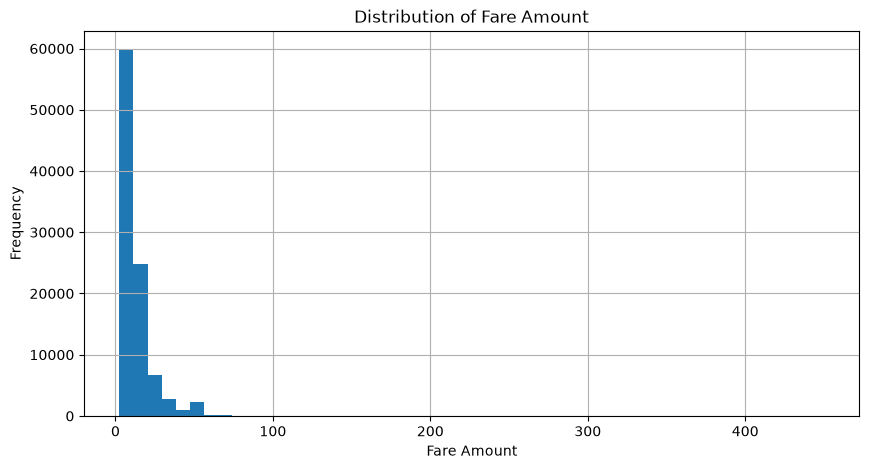

In [231]:
df["fare_amount"].hist(bins=50, figsize=(10, 5))

plt.xlabel("Fare Amount")
plt.ylabel("Frequency")
plt.title("Distribution of Fare Amount")
plt.show()

**Observation:** `fare_amount` is strongly right-skewed. Most trips have relatively low fares, while a small number of trips have much higher fares that require further outlier analysis.

### 3.3 Feature Distributions

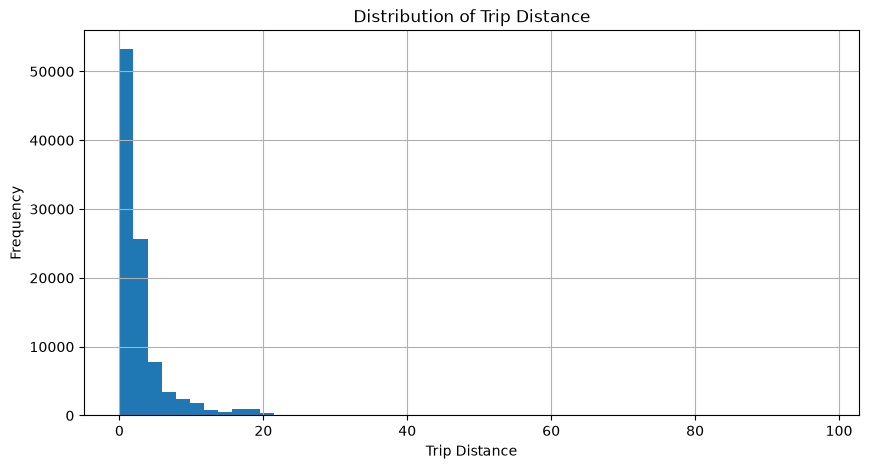

In [232]:
df["trip_distance"].hist(bins=50, figsize=(10, 5))

plt.xlabel("Trip Distance")
plt.ylabel("Frequency")
plt.title("Distribution of Trip Distance")
plt.show()

**Observation:** `trip_distance` is strongly right-skewed. Most trips are relatively short, while a small number of trips have much larger distances that require further outlier analysis.

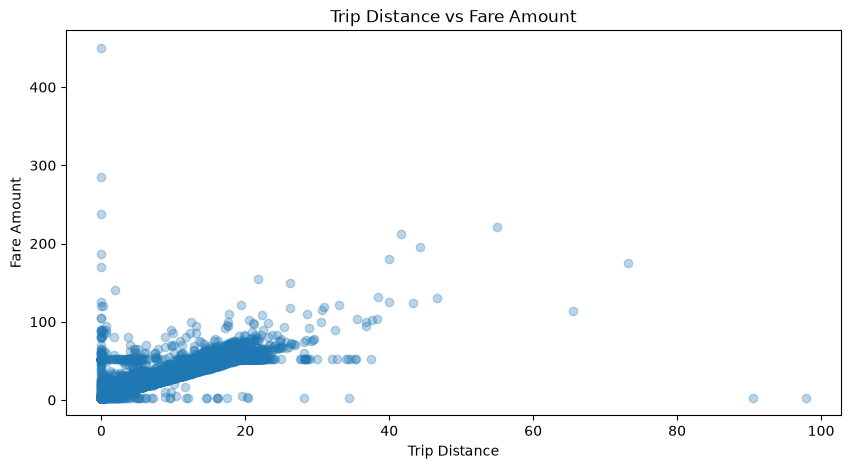

In [233]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df["trip_distance"],
    df["fare_amount"],
    alpha=0.3
)

plt.xlabel("Trip Distance")
plt.ylabel("Fare Amount")
plt.title("Trip Distance vs Fare Amount")

plt.show()

**Observation:** `trip_distance` shows a clear positive relationship with `fare_amount`. In general, longer trips tend to have higher fares, although some extreme observations are present and will be investigated during outlier analysis.

### 3.5 Outlier Analysis

In [234]:
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1: {Q1}")
print(f"Q3: {Q3}")
print(f"IQR: {IQR}")
print(f"Lower Bound: {lower_bound}")
print(f"Upper Bound: {upper_bound}")

Q1: 6.5
Q3: 14.5
IQR: 8.0
Lower Bound: -5.5
Upper Bound: 26.5


In [235]:
fare_outliers = df[df["fare_amount"] > upper_bound]

print(f"Number of potential outliers: {len(fare_outliers)}")
print(f"Percentage of potential outliers: {len(fare_outliers) / len(df) * 100:.2f}%")

Number of potential outliers: 7728
Percentage of potential outliers: 7.90%


**Observation:** The IQR method identifies 7,689 potential fare outliers (7.87% of the dataset). Since this is a substantial proportion, these observations will be investigated rather than removed automatically.

In [236]:
Q1_distance = df["trip_distance"].quantile(0.25)
Q3_distance = df["trip_distance"].quantile(0.75)

IQR_distance = Q3_distance - Q1_distance

lower_bound_distance = Q1_distance - 1.5 * IQR_distance
upper_bound_distance = Q3_distance + 1.5 * IQR_distance

print(f"Q1: {Q1_distance}")
print(f"Q3: {Q3_distance}")
print(f"IQR: {IQR_distance}")
print(f"Lower Bound: {lower_bound_distance}")
print(f"Upper Bound: {upper_bound_distance}")

Q1: 1.05
Q3: 3.23
IQR: 2.1799999999999997
Lower Bound: -2.2199999999999998
Upper Bound: 6.5


In [237]:
distance_outliers = df[df["trip_distance"] > upper_bound_distance]

print(f"Number of potential outliers: {len(distance_outliers)}")
print(f"Percentage of potential outliers: {len(distance_outliers) / len(df) * 100:.2f}%")

Number of potential outliers: 9768
Percentage of potential outliers: 9.98%


**Observation:** The IQR method identifies 9,768 potential trip-distance outliers (9.98% of the dataset). Since this represents a substantial proportion of the data, these observations will be retained for further analysis rather than removed automatically.

## 4. Feature Engineering

We transform raw trip information into meaningful features that can help the model predict taxi fares.

### 4.1 Datetime Features

We extract useful time-based features from `pickup_datetime`, such as hour, day, month, and day of the week.

In [238]:
df["pickup_hour"] = df["pickup_datetime"].dt.hour
df["pickup_day"] = df["pickup_datetime"].dt.day
df["pickup_month"] = df["pickup_datetime"].dt.month
df["pickup_day_of_week"] = df["pickup_datetime"].dt.dayofweek

df["pickup_is_weekend"] = (
    df["pickup_day_of_week"].isin([5, 6]).astype(int)
)

In [239]:
df[
    [
        "pickup_datetime",
        "pickup_hour",
        "pickup_day",
        "pickup_month",
        "pickup_day_of_week",
        "pickup_is_weekend"
    ]
].head()

,pickup_datetime,pickup_hour,pickup_day,pickup_month,pickup_day_of_week,pickup_is_weekend
1,2014-04-16 13:45:06,13,16,4,2,0
2,2014-02-09 22:43:54,22,9,2,6,1
3,2014-10-27 23:15:23,23,27,10,0,0
4,2014-09-14 01:32:00,1,14,9,6,1
5,2014-02-21 22:52:00,22,21,2,4,0


In [240]:
df["is_rush_hour"] = (
    df["pickup_hour"].isin([7, 8, 9, 16, 17, 18, 19])
).astype(int)

In [241]:
df["is_rush_hour"].value_counts()

is_rush_hour
0    64733
1    33103
Name: count, dtype: int64

In [242]:
df["is_rush_hour"].value_counts(normalize=True) * 100

is_rush_hour
0    66.164806
1    33.835194
Name: proportion, dtype: float64

In [243]:
pd.crosstab(
    df["pickup_hour"],
    df["is_rush_hour"]
)

is_rush_hour,0,1
pickup_hour,,
0,3978,0
1,2751,0
2,2199,0
3,1492,0
4,1164,0
5,961,0
6,2107,0
7,0,3551
8,0,4398


### 4.2 Geospatial Features

In [244]:
import numpy as np

In [245]:
lat1 = np.radians(df["pickup_latitude"])
lon1 = np.radians(df["pickup_longitude"])

lat2 = np.radians(df["dropoff_latitude"])
lon2 = np.radians(df["dropoff_longitude"])

dlat = lat2 - lat1
dlon = lon2 - lon1

a = (
    np.sin(dlat / 2) ** 2
    + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
)

c = 2 * np.arcsin(np.sqrt(a))

earth_radius_km = 6371

df["geodesic_distance_km"] = earth_radius_km * c

In [246]:
df["geodesic_distance_km"].describe()

count    97836.000000
mean         3.502908
std         19.397399
min          0.000000
25%          1.275143
50%          2.181767
75%          3.996572
max       5952.026168
Name: geodesic_distance_km, dtype: float64

In [247]:
df[df["geodesic_distance_km"] > 100][
    [
        "pickup_latitude",
        "pickup_longitude",
        "dropoff_latitude",
        "dropoff_longitude",
        "geodesic_distance_km",
        "fare_amount"
    ]
].head()

,pickup_latitude,pickup_longitude,dropoff_latitude,dropoff_longitude,geodesic_distance_km,fare_amount
47446,40.794827,-73.969778,40.801145,-0.96527,5952.026168,4.0


In [248]:
(df["geodesic_distance_km"] > 100).sum()

np.int64(1)

In [249]:
df = df[df["geodesic_distance_km"] <= 100].copy()

In [250]:
df["geodesic_distance_km"].describe()

count    97835.000000
mean         3.442107
std          3.817838
min          0.000000
25%          1.275124
50%          2.181731
75%          3.996512
max         89.166764
Name: geodesic_distance_km, dtype: float64

In [251]:
df["is_same_location"] = (
    df["geodesic_distance_km"] < 0.1
).astype(int)

In [252]:
df["is_same_location"].value_counts()

is_same_location
0    96687
1     1148
Name: count, dtype: int64

**Observation:** Geospatial features were created using the pickup and dropoff coordinates. A small number of trips have pickup and dropoff locations within 100 meters of each other.

### 4.3 Categorical Features

Categorical features are converted into numerical representations so they can be used by machine learning models.

In [253]:
df[["vendor_id", "payment_type", "store_and_fwd_flag"]].nunique()

vendor_id             2
payment_type          5
store_and_fwd_flag    3
dtype: int64

In [254]:
for col in ["vendor_id", "payment_type", "store_and_fwd_flag"]:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))


vendor_id:
vendor_id
VTS    50193
CMT    47642
Name: count, dtype: int64

payment_type:
payment_type
CRD    56918
CSH    40135
UNK      444
NOC      258
DIS       80
Name: count, dtype: int64

store_and_fwd_flag:
store_and_fwd_flag
Unknown    50193
N          46585
Y           1057
Name: count, dtype: int64


### 4.4 Feature Selection

We select the features that are relevant for predicting `fare_amount` and exclude target-related and post-trip information to avoid data leakage.

In [255]:
target = "fare_amount"

features = [
    "vendor_id",
    "passenger_count",
    "trip_distance",
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude",
    "store_and_fwd_flag",
    "payment_type",
    "rate_code",
    "pickup_hour",
    "pickup_day",
    "pickup_month",
    "pickup_day_of_week",
    "pickup_is_weekend",
    "geodesic_distance_km",
    "is_same_location"
]

X = df[features]
y = df[target]

In [256]:
X.shape, y.shape

((97835, 17), (97835,))

### 4.5 Train-Test Split

The dataset is split into training and testing sets to train the model and evaluate its performance on unseen data.

In [257]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [258]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [259]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (78268, 17)
X_test: (19567, 17)
y_train: (78268,)
y_test: (19567,)


### 4.6 Encoding Categorical Features

Categorical features are encoded using One-Hot Encoding so they can be used by machine learning models.

In [260]:
categorical_features = [
    "vendor_id",
    "store_and_fwd_flag",
    "payment_type",
    "rate_code"
]

numeric_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

In [261]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", "passthrough", numeric_features)
    ]
)

## 5. Model Building

We train machine learning models to predict `fare_amount`.

### 5.1 Linear Regression

In [262]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

In [263]:
linear_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['vendor_id','passenger_count','trip_distance',...,'pickup_is_weekend', 'geodesic_distance_km','is_same_location']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatic

In [264]:
linear_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['vendor_id','passenger_count','trip_distance',...,'pickup_is_weekend', 'geodesic_distance_km','is_same_location']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatic

In [265]:
y_pred_lr = linear_model.predict(X_test)

In [266]:
print(y_pred_lr[:10])

[ 7.41458317  7.01368467  6.93743268 12.4093378   7.59675111 12.87789048
 24.12324572 13.00133711 16.07434987  5.85515751]


In [267]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred_lr
})

comparison.head(10)

,Actual,Predicted
0,5.5,7.414583
1,7.0,7.013685
2,4.5,6.937433
3,10.5,12.409338
4,9.0,7.596751
5,13.0,12.877890
6,24.0,24.123246
7,15.0,13.001337
8,20.0,16.074350
9,5.0,5.855158


In [268]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred_lr)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2 = r2_score(y_test, y_pred_lr)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 1.7737711570439745
RMSE: 2.9953818451697036
R²: 0.9125211284273826


**Observation:** The Linear Regression model achieved an MAE of 1.77, RMSE of 3.00, and R² of 0.913. This provides a strong baseline for comparing more advanced models.

### 5.2 Random Forest

We use Random Forest Regressor as a non-linear model to compare its performance with Linear Regression.

In [269]:
from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [ ]:
rf_model.fit(X_train, y_train)

In [ ]:
y_pred_rf = rf_model.predict(X_test)

In [ ]:
print(y_pred_rf[:10])

[11.055  8.625  5.36   7.945  8.885  8.415 13.29   8.525 17.29   7.875]


### 5.3 Model Comparison

The performance of the two models is compared using MAE, RMSE, and R².

In [ ]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred_rf
})

comparison.head(10)

,Actual,Predicted
0,12.5,11.055
1,8.0,8.625
2,5.0,5.360
3,8.0,7.945
4,8.0,8.885
5,9.0,8.415
6,16.0,13.290
7,13.0,8.525
8,16.0,17.290
9,9.0,7.875


In [ ]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R²:", r2_rf)

MAE: 1.2457927651089067
RMSE: 2.2588826005909155
R²: 0.9500228399322934


In [ ]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, mae_rf],
    "RMSE": [rmse, rmse_rf],
    "R²": [r2, r2_rf]
})

results

,Model,MAE,RMSE,R²
0,Linear Regression,1.698988,3.092033,0.906358
1,Random Forest,1.245793,2.258883,0.950023


**Observation:** Random Forest achieved lower MAE and RMSE and a higher R² than Linear Regression on the test set.

## 6. Model Building From Scratch

### 6.1 Linear Regression From Scratch


#### 6.1.1 Data Preparation

The data is prepared by encoding categorical features and converting the datasets into NumPy arrays.


In [ ]:
X_train_scratch = pd.get_dummies(
    X_train,
    columns=categorical_features,
    dtype=int
)

X_test_scratch = pd.get_dummies(
    X_test,
    columns=categorical_features,
    dtype=int
)

In [ ]:
X_train_scratch, X_test_scratch = X_train_scratch.align(
    X_test_scratch,
    join="left",
    axis=1,
    fill_value=0
)

In [ ]:
X_train_scratch = X_train_scratch.values
X_test_scratch = X_test_scratch.values

y_train_scratch = y_train.values
y_test_scratch = y_test.values

In [ ]:
print("X_train:", X_train_scratch.shape)
print("X_test:", X_test_scratch.shape)
print("y_train:", y_train_scratch.shape)
print("y_test:", y_test_scratch.shape)

X_train: (78230, 29)
X_test: (19558, 29)
y_train: (78230,)
y_test: (19558,)


### 6.1.2 Model Implementation

In [ ]:
import numpy as np

X_train_scratch = np.c_[
    np.ones(X_train_scratch.shape[0]),
    X_train_scratch
]

X_test_scratch = np.c_[
    np.ones(X_test_scratch.shape[0]),
    X_test_scratch
]

In [ ]:
weights = np.zeros(X_train_scratch.shape[1])

In [ ]:
print("Number of weights:", len(weights))

Number of weights: 30


In [ ]:
def predict(X, weights):
    return X @ weights

#### 6.1.3 Cost Function

The Mean Squared Error is used as the cost function to measure the difference between predicted and actual fare values.

In [ ]:
def compute_cost(X, y, weights):
    predictions = predict(X, weights)
    errors = predictions - y
    
    cost = np.mean(errors ** 2) / 2
    
    return cost

#### 6.1.4 Feature Scaling

Feature scaling is applied to numerical features to keep their values on a similar scale and improve the stability of Gradient Descent.

In [ ]:
X_mean = X_train_scratch[:, 1:].mean(axis=0)
X_std = X_train_scratch[:, 1:].std(axis=0)

X_std[X_std == 0] = 1

X_train_scaled = X_train_scratch.copy()
X_test_scaled = X_test_scratch.copy()

X_train_scaled[:, 1:] = (
    X_train_scratch[:, 1:] - X_mean
) / X_std

X_test_scaled[:, 1:] = (
    X_test_scratch[:, 1:] - X_mean
) / X_std

#### 6.1.5 Gradient Descent

Gradient Descent is used to update the model weights and minimize the cost function during training.

In [ ]:
def train_linear_regression(X, y, learning_rate=0.01, epochs=1000):
    weights = np.zeros(X.shape[1])
    
    for _ in range(epochs):
        predictions = predict(X, weights)
        errors = predictions - y
        
        gradients = (X.T @ errors) / len(y)
        
        weights -= learning_rate * gradients
    
    return weights

In [ ]:
weights = train_linear_regression(
    X_train_scaled,
    y_train_scratch,
    learning_rate=0.01,
    epochs=1000
)

In [ ]:
print(weights[:10])

[ 1.25446181e+01  3.25337358e-02  6.00520097e+00 -6.70169163e-02
  2.17029993e-01 -9.64783142e-02 -2.62775014e-01  1.09361208e-01
  9.69899018e-04  1.33001761e-01]


#### 6.1.5 Prediction

The trained model is used to predict taxi fares on the test set.

In [ ]:
y_pred_scratch = predict(
    X_test_scaled,
    weights
)

In [ ]:
print(y_pred_scratch[:10])

[10.32126692 10.10022206  6.25181092  7.94834821  9.02334357  8.53786992
 13.39366108  8.30993533 17.53910342  7.27726256]


In [ ]:
comparison_scratch = pd.DataFrame({
    "Actual": y_test_scratch,
    "Predicted": y_pred_scratch
})

comparison_scratch.head(10)

,Actual,Predicted
0,12.5,10.321267
1,8.0,10.100222
2,5.0,6.251811
3,8.0,7.948348
4,8.0,9.023344
5,9.0,8.537870
6,16.0,13.393661
7,13.0,8.309935
8,16.0,17.539103
9,9.0,7.277263


In [ ]:
mae_scratch = mean_absolute_error(
    y_test_scratch,
    y_pred_scratch
)

rmse_scratch = np.sqrt(
    mean_squared_error(
        y_test_scratch,
        y_pred_scratch
    )
)

r2_scratch = r2_score(
    y_test_scratch,
    y_pred_scratch
)

print("MAE:", mae_scratch)
print("RMSE:", rmse_scratch)
print("R²:", r2_scratch)

MAE: 1.7847096765108275
RMSE: 3.1565247541826595
R²: 0.9024105989633264


In [ ]:
comparison_models = pd.DataFrame({
    "Model": [
        "Linear Regression - Sklearn",
        "Linear Regression - From Scratch"
    ],
    "MAE": [
        mae,
        mae_scratch
    ],
    "RMSE": [
        rmse,
        rmse_scratch
    ],
    "R²": [
        r2,
        r2_scratch
    ]
})

comparison_models

,Model,MAE,RMSE,R²
0,Linear Regression - Sklearn,1.698988,3.092033,0.906358
1,Linear Regression - From Scratch,1.784710,3.156525,0.902411


**Observation:** The Linear Regression model implemented from scratch achieved performance close to the Scikit-learn implementation, with slightly higher MAE and RMSE and a slightly lower R².

### 6.2 Random Forest From Scratch